# General

## Imports

In [8]:
### Time frames - Define the start and end dates of the data that you want to look at (e.g. all 29 years between 1996 and 2025) (ICMECAT only goes to mid-2025 for now)
dataTimeframe = ["1996-01-01 00:00", "2025-01-01 00:00"]
start = dataTimeframe[0] # start date of data
end = dataTimeframe[1] # end date of data
dataSourcesToUse = ["Wind"]

import numpy as np 
import os
import pandas as pd
import calendar
import warnings
warnings.filterwarnings("ignore")

## Functions

In [9]:
def Yearly(startDate, endDate, frequency = 'YS'): #ReadDatesForFileFinding - Gets range of dates in given frequency to use to get the data files.
    YearlyRange = pd.date_range(startDate, endDate, freq=frequency).strftime("%Y%m%d").tolist()
    return YearlyRange

# Get to date portion of the file names
def myFunc(e):
  return e.split("b")[1]

# Wind: Get the pre-downloaded data from folder
def FindDataWind(directory, dataName, startDate, endDate, frequency = 'MS'): #FindDataMakeTimeSeries
    files = []
    for file in os.listdir(directory):
        filename = os.fsdecode(file)
        DateRange = pd.date_range(startDate, endDate, freq=frequency).strftime("%Y%m%d").tolist()
        for j in range(len(DateRange)):
            if filename.startswith(dataName + str(DateRange[j])[0:6]):
                files.append(directory+filename)
                continue
    filesSorted = sorted(files, key=myFunc) # sort files
    wind_list = [] #pd.DataFrame([])
    # Columns from https://omniweb.gsfc.nasa.gov/html/HROdocum.html
    colnames = ["Year", "DOY", "Hour", "Minute", "IMF_PTS", "PercentInterp", "CP/MVFlag", "Timeshift", 
                "PFN_XGSE", "PFN_YGSE","PFN_ZGSE", "ScalarB", "Bx_GSEGSM", "ByGSE", "BzGSE", "ByGSM", "BzGSM", 
                "RMSTimeshift", "RMS_PFN", "RMSScalarB", "RMSFieldVector", "Plasma_PTS", "FlowSpeed",
                "Vx_GSE", "Vy_GSE", "Vz_GSE", "ProtonDensity", "Temp", "X_s_c_GSE", "Y_s_c_GSE", "Z_s_c_GSE",
                 "X_targ_GSE", "Y_targ_GSE", "Z_targ_GSE", "RMS_targ", "DBOT1", "DBOT2"]
    for j in range(len(filesSorted)):
        wind_list.append( pd.read_csv(filesSorted[j], header=None, sep = r"\s+", names = colnames) )
    wind_monthly = pd.concat(wind_list, ignore_index=True)
    # Laura's code
    wind_monthly.index = (pd.to_datetime(wind_monthly["Year"].astype(str), format="%Y")
                + pd.to_timedelta(wind_monthly["DOY"] - 1, unit="D")
                + pd.to_timedelta(wind_monthly["Hour"], unit="h")
                + pd.to_timedelta(wind_monthly["Minute"], unit="min"))
    fill_values = {"ScalarB": 9999.99, "Bx_GSEGSM": 9999.99, "ByGSE": 9999.99, "BzGSE": 9999.99,
                   "FlowSpeed": 99999.9, "Vx_GSE": 99999.9, "Vy_GSE": 99999.9, "Vz_GSE": 99999.9,
                   "ProtonDensity": 999.99, "Temp": 9999999.0,
                   'X_s_c_GSE': 9999.99,'Y_s_c_GSE': 9999.99, 'Z_s_c_GSE': 9999.99,
                   'X_targ_GSE': 9999.99, 'Y_targ_GSE': 9999.99, 'Z_targ_GSE': 9999.99}
    for column, fill in fill_values.items():
        wind_monthly.loc[wind_monthly[column] >= fill, column] = np.nan
    return wind_monthly


# Wind

In [10]:
### Wind
if "Wind" in dataSourcesToUse:
    #### Places to get and save files
    DataDirectory = "Data/windData/"
    dataName = "wind_min_b"
    ##### Details: Yearly, minutely data, bow-shock shifted

    # Get data files
    windData = [] # empty array for wind data
    start = dataTimeframe[0] # start date of data
    end = dataTimeframe[1] # end date of data

    yearlyRange = Yearly(start, end, frequency = 'MS') # Get range of dates needed (monthly as the downloaded data files are monthly)
    print(yearlyRange)
    for i in range(len(yearlyRange)-1): # for each date range in time range needed
        StartDate = yearlyRange[i] # first file in range
        dow, numberOfDays = calendar.monthrange(int(yearlyRange[i][0:4]), int(yearlyRange[i][4:6])) #dow = day of week, not needed value
        EndDate = yearlyRange[i][0:6] + str(numberOfDays) # last file in range 
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        windData.append(dataFound) # add each month of data to the data array

    list_of_monthly_data = [] # create a list for the data frames
    for i in range(len(windData)): #for each monthly timeseries
        list_of_monthly_data.append(windData[i]) # add them to the list as dataframes
    windDataConcat = pd.concat(list_of_monthly_data) # concatenate all the monthly dataframes together to make one large dataframe for the full data timespan

else:
    print("Not processing Wind data")


['19960101', '19960201', '19960301', '19960401', '19960501', '19960601', '19960701', '19960801', '19960901', '19961001', '19961101', '19961201', '19970101', '19970201', '19970301', '19970401', '19970501', '19970601', '19970701', '19970801', '19970901', '19971001', '19971101', '19971201', '19980101', '19980201', '19980301', '19980401', '19980501', '19980601', '19980701', '19980801', '19980901', '19981001', '19981101', '19981201', '19990101', '19990201', '19990301', '19990401', '19990501', '19990601', '19990701', '19990801', '19990901', '19991001', '19991101', '19991201', '20000101', '20000201', '20000301', '20000401', '20000501', '20000601', '20000701', '20000801', '20000901', '20001001', '20001101', '20001201', '20010101', '20010201', '20010301', '20010401', '20010501', '20010601', '20010701', '20010801', '20010901', '20011001', '20011101', '20011201', '20020101', '20020201', '20020301', '20020401', '20020501', '20020601', '20020701', '20020801', '20020901', '20021001', '20021101', '20

In [11]:
### Wind
if "Wind" in dataSourcesToUse:
    print(windDataConcat)
    windDataConcat.to_csv("Wind_" + str(start)[0:10] + "-" + str(end)[0:10]+ "_InputOutput.csv")
else:
    print("Not processing Wind data")

                     Year  DOY  Hour  Minute  IMF_PTS  PercentInterp  \
1996-01-01 00:00:00  1996    1     0       0        2            100   
1996-01-01 00:01:00  1996    1     0       1        2            100   
1996-01-01 00:02:00  1996    1     0       2        1            100   
1996-01-01 00:03:00  1996    1     0       3        1            100   
1996-01-01 00:04:00  1996    1     0       4        1            100   
...                   ...  ...   ...     ...      ...            ...   
2024-12-31 23:55:00  2024  366    23      55      999            999   
2024-12-31 23:56:00  2024  366    23      56        1            100   
2024-12-31 23:57:00  2024  366    23      57        1            100   
2024-12-31 23:58:00  2024  366    23      58      999            999   
2024-12-31 23:59:00  2024  366    23      59        1            100   

                     CP/MVFlag  Timeshift  PFN_XGSE  PFN_YGSE  ...     Temp  \
1996-01-01 00:00:00        9.9       1258      0.62     

### Wind test

In [12]:
testData = pd.read_csv("Wind_" + str(start)[0:10] + "-" + str(end)[0:10]+ "_InputOutput.csv", index_col=["Unnamed: 0"])

In [13]:
print(testData[0:10])
# print(testData["Unnamed: 0"][0:10])
# print(testData.columns)

                     Year  DOY  Hour  Minute  IMF_PTS  PercentInterp  \
1996-01-01 00:00:00  1996    1     0       0        2            100   
1996-01-01 00:01:00  1996    1     0       1        2            100   
1996-01-01 00:02:00  1996    1     0       2        1            100   
1996-01-01 00:03:00  1996    1     0       3        1            100   
1996-01-01 00:04:00  1996    1     0       4        1            100   
1996-01-01 00:05:00  1996    1     0       5        1            100   
1996-01-01 00:06:00  1996    1     0       6        8             50   
1996-01-01 00:07:00  1996    1     0       7       10            100   
1996-01-01 00:08:00  1996    1     0       8       12             58   
1996-01-01 00:09:00  1996    1     0       9       14             50   

                     CP/MVFlag  Timeshift  PFN_XGSE  PFN_YGSE  ...     Temp  \
1996-01-01 00:00:00        9.9       1258      0.62     -0.41  ...      NaN   
1996-01-01 00:01:00        9.9       1307      0.

<Axes: >

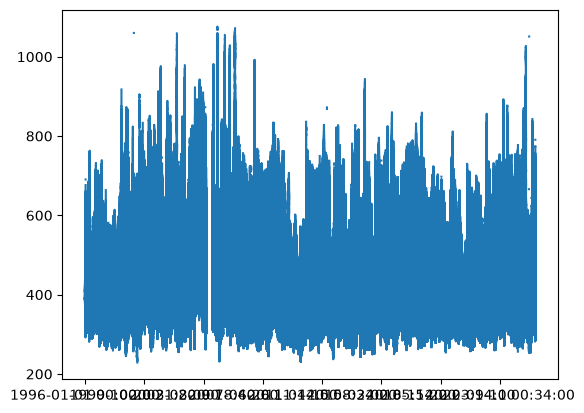

In [14]:
# Test that the full data range is plotted
testData["FlowSpeed"].plot() # Note this is not the total solar wind speed that we will use, this is just to test the data has loaded correctly

# x = (2026-1996) * 365.25 * 24 * 60
# print(x)